In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

df = pd.read_csv("data.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:

# Remove ID, diagnosis, and empty column
X = df.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)

# Standardize numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Number of samples:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])
print("Data preprocessing completed!")


Number of samples: 569
Number of features: 30
Data preprocessing completed!


In [4]:

k_values = range(1, 11)
wcss = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    wcss.append(model.inertia_)

elbow_df = pd.DataFrame({
    "Number of Clusters": list(k_values),
    "WCSS": wcss
})

print("ELBOW METHOD RESULTS")
display(elbow_df.round(2))


ELBOW METHOD RESULTS


,Number of Clusters,WCSS
0,1,17070.00
1,2,11595.53
2,3,10061.80
3,4,9258.99
4,5,8558.66
5,6,7970.26
6,7,7540.32
7,8,7254.33
8,9,6837.63
9,10,6603.40


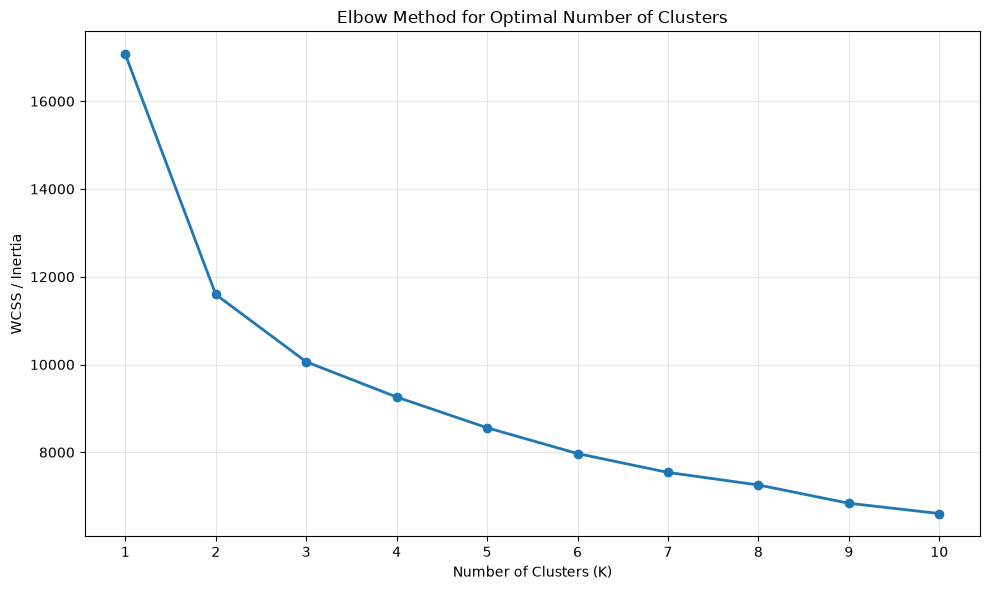

In [5]:

plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    wcss,
    marker="o",
    linewidth=2
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [6]:

silhouette_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    silhouette_results.append({
        "K Value": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

print("SILHOUETTE SCORE RESULTS")
display(silhouette_df.round(4))

best_k = int(
    silhouette_df.loc[
        silhouette_df["Silhouette Score"].idxmax(),
        "K Value"
    ]
)

print("\nBest K based on Silhouette Score:", best_k)


SILHOUETTE SCORE RESULTS


,K Value,Silhouette Score
0,2,0.3434
1,3,0.3144
2,4,0.2833
3,5,0.1582
4,6,0.1604
5,7,0.1532
6,8,0.1472
7,9,0.1470
8,10,0.1367



Best K based on Silhouette Score: 2


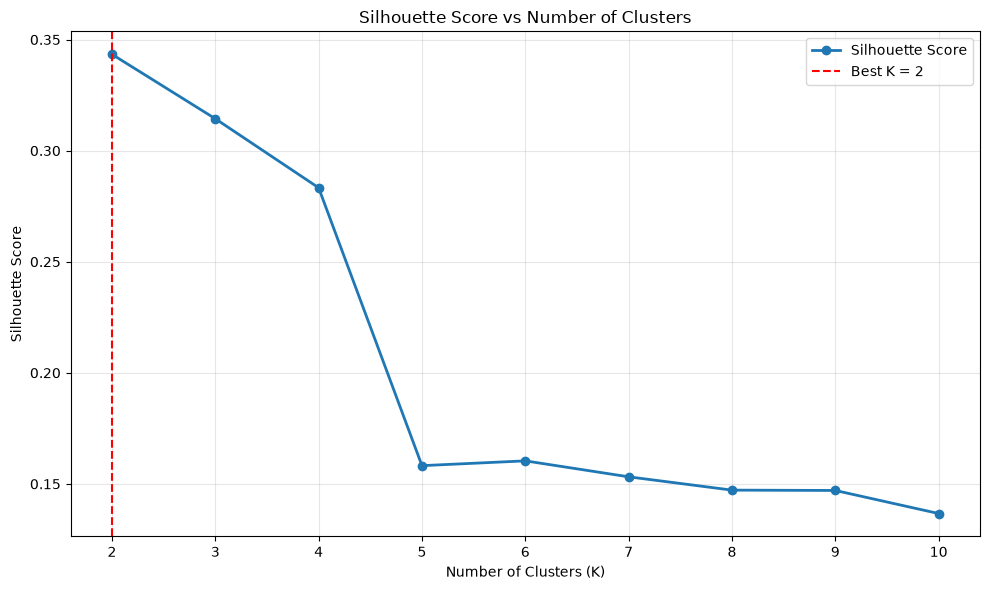

In [7]:

plt.figure(figsize=(10, 6))

plt.plot(
    silhouette_df["K Value"],
    silhouette_df["Silhouette Score"],
    marker="o",
    linewidth=2,
    label="Silhouette Score"
)

plt.axvline(
    best_k,
    color="red",
    linestyle="--",
    label=f"Best K = {best_k}"
)

plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [8]:

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = final_model.fit_predict(X_scaled)

print("K-MEANS CLUSTERING RESULTS")
print("Optimal number of clusters:", best_k)

cluster_counts = pd.Series(
    cluster_labels,
    name="Cluster"
).value_counts().sort_index()

print("\nSamples in each cluster:")
display(cluster_counts)


K-MEANS CLUSTERING RESULTS
Optimal number of clusters: 2

Samples in each cluster:


Cluster
0    375
1    194
Name: count, dtype: int64

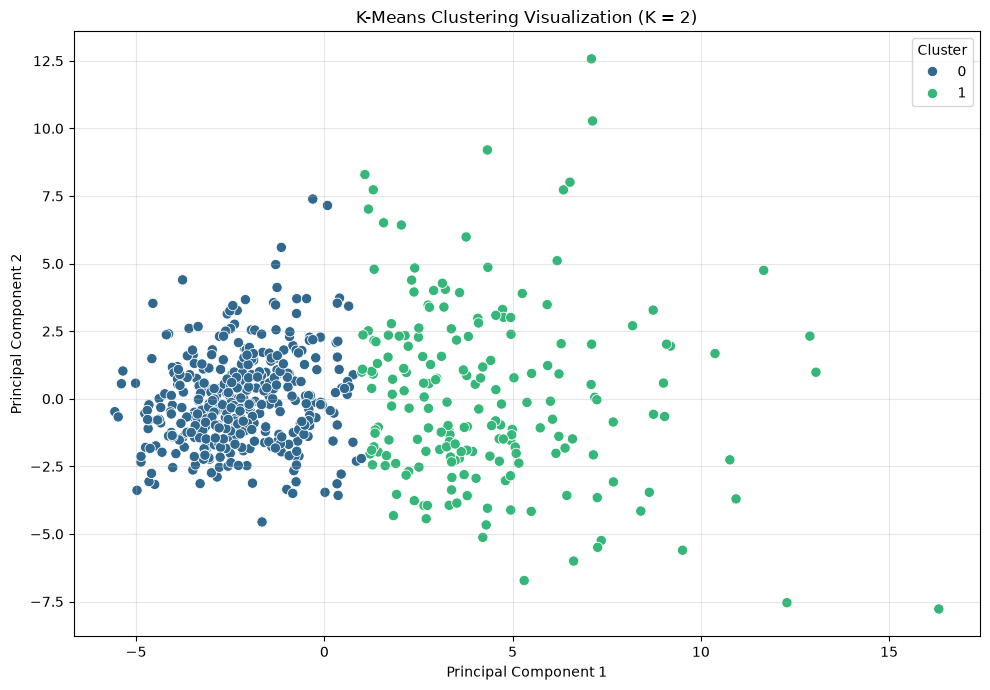

In [9]:

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=cluster_labels,
    palette="viridis",
    s=55
)

plt.title(f"K-Means Clustering Visualization (K = {best_k})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

best_score = silhouette_df["Silhouette Score"].max()

print("=" * 45)
print("K-MEANS CLUSTERING FINAL RESULT")
print("=" * 45)

print("Optimal Number of Clusters:", best_k)
print("Best Silhouette Score:", round(best_score, 4))
print("Final WCSS:", round(final_model.inertia_, 2))
print("Number of Samples:", len(X_scaled))

print("\nExperiment Completed Successfully!")


K-MEANS CLUSTERING FINAL RESULT
Optimal Number of Clusters: 2
Best Silhouette Score: 0.3434
Final WCSS: 11595.53
Number of Samples: 569

Experiment Completed Successfully!
